# 02 - Features and segmentation
## Part 1: Leak-free labels and customer features
Features use only transactions **before** the cutoff; labels use only transactions **after** it. Only ACTIVE customers (a purchase in the 180 days before the cutoff) are kept. All logic is in `src/`.

In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import config
import snapshots

pd.set_option('display.width', 250)
print('Train cutoff:', config.TRAIN_CUTOFF.date(), '  Test cutoff:', config.TEST_CUTOFF.date())
print('Churn window:', config.CHURN_WINDOW_DAYS, 'days   Spend window:', config.SPEND_WINDOW_MONTHS, 'months   Active window:', config.ACTIVE_WINDOW_DAYS, 'days')

Train cutoff: 2010-12-01   Test cutoff: 2011-06-01
Churn window: 90 days   Spend window: 6 months   Active window: 180 days


### Choosing the train cutoff
Candidate cutoffs, active customers only, with a recency-only baseline (churn if recency > median).

In [2]:
tx, cancels = snapshots.load_clean_data()
candidates = [pd.Timestamp('2010-06-01'), pd.Timestamp('2010-09-01'), config.TRAIN_CUTOFF]
comparison = snapshots.compare_cutoffs(tx, cancels, candidates, config.TEST_CUTOFF)
comparison.to_csv(config.TABLES_DIR / 'cutoff_comparison_active.csv', index=False)
comparison

,role,cutoff,ends_before_test,history_months,customers,churn_rate,spend_mean,spend_median,spend_zero_share,median_recency,baseline_precision,baseline_recall,baseline_f1,recency_roc_auc
0,train?,2010-06-01,True,6.0,2652,0.50,1373.3,450.6,0.280,43.5,0.608,0.608,0.608,0.649
1,train?,2010-09-01,True,9.0,2822,0.38,1254.9,380.8,0.316,57.3,0.477,0.628,0.542,0.636
2,train?,2010-12-01,True,12.0,3465,0.62,793.6,127.8,0.461,34.5,0.726,0.585,0.648,0.661
3,test,2011-06-01,True,18.0,2658,0.50,1444.3,406.6,0.298,48.4,0.628,0.628,0.628,0.660


We keep **2010-12-01**: it has 12 months of history, and recency predicts churn equally well there and in the test snapshot (ROC-AUC 0.661 vs 0.660). Known issues: train churn rate 0.62 vs test 0.50 (the post-Christmas window), and the spend windows are in different seasons (see `reports/RESULTS_NOTES.md`).

### Build the out-of-time train and test tables

In [3]:
train, test = snapshots.build_train_test_tables()

Saved train_table.parquet (cutoff 2010-12-01)


Saved test_table.parquet (cutoff 2011-06-01)

--- TRAIN ---
Customers:                 3,465
Churn rate:                0.620  (churn=1: 2,147, churn=0: 1,318)
future_spend = 0:          1,596 customers (46.1%)
future_spend summary (GBP):
count      3465.0
mean        793.6
std        3550.5
min           0.0
25%           0.0
50%         127.8
75%         647.3
90%        1629.0
99%        7688.7
max      110155.1

--- TEST ---
Customers:                 2,658
Churn rate:                0.500  (churn=1: 1,330, churn=0: 1,328)
future_spend = 0:          792 customers (29.8%)
future_spend summary (GBP):
count      2658.0
mean       1444.3
std        6726.5
min           0.0
25%           0.0
50%         406.6
75%        1226.6
90%        2616.5
99%       14988.7
max      183529.6



In [4]:
train.head()

,recency,frequency,monetary,avg_order_value,avg_gap_days,tenure_days,unique_products,return_rate,spend_trend,purchase_regularity,is_uk,is_single_order,churn,future_spend
customer_id,,,,,,,,,,,,,,
12346,155.421528,2,169.36,84.68,118.031250,273.452778,24,0.000000,0.000000,0.0,1,0,0,77183.60
12347,30.402778,1,611.53,611.53,30.402778,30.402778,40,0.000000,1.000000,0.0,0,1,0,1823.43
12348,64.375694,1,221.16,221.16,64.375694,64.375694,19,0.000000,1.000000,0.0,0,1,0,1167.24
12349,33.650694,2,2221.14,1110.57,181.793750,215.444444,89,0.333333,0.518932,0.0,0,0,1,0.00
12351,1.359028,1,300.93,300.93,1.359028,1.359028,21,0.000000,1.000000,0.0,0,1,1,0.00


In [5]:
train.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
recency,3465.0,48.28,45.52,0.18,12.49,34.51,68.51,179.59
frequency,3465.0,4.90,8.17,1.00,1.00,3.00,5.00,175.00
monetary,3465.0,2273.49,9333.92,3.75,372.06,873.25,1965.52,321329.74
avg_order_value,3465.0,385.66,476.09,3.75,191.07,296.65,435.60,11880.84
avg_gap_days,3465.0,71.21,60.78,0.00,28.95,54.04,94.07,363.89
tenure_days,3465.0,203.50,122.40,0.22,77.34,217.43,316.47,364.62
unique_products,3465.0,71.15,90.27,1.00,21.00,45.00,90.00,1712.00
return_rate,3465.0,0.12,0.17,0.00,0.00,0.00,0.25,0.83
spend_trend,3465.0,0.50,0.37,0.00,0.21,0.44,1.00,1.00
purchase_regularity,3465.0,24.06,34.83,0.00,0.00,9.88,36.41,251.98


## Part 2: K-Means customer segmentation
RFM = recency, frequency, monetary. Frequency and monetary are log1p-transformed (skew 8.8 and 21.6); recency is kept as is (skew 1.2, capped at 180 days by the active filter). The scaler and K-Means are fitted on TRAIN only.

In [6]:
import segmentation

k_scores = segmentation.evaluate_k(train)
k_scores.to_csv(config.TABLES_DIR / 'kmeans_k_selection.csv', index=False)
k_scores.round(3)

,k,inertia,silhouette
0,2,5937.642,0.374
1,3,4065.725,0.383
2,4,3127.519,0.345
3,5,2676.599,0.341
4,6,2285.129,0.315
5,7,2067.210,0.304
6,8,1862.115,0.309
7,9,1693.224,0.293
8,10,1577.427,0.291


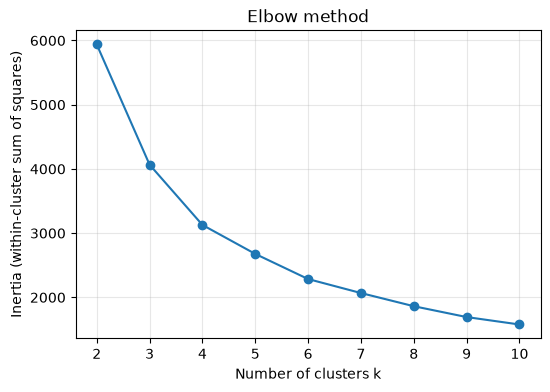

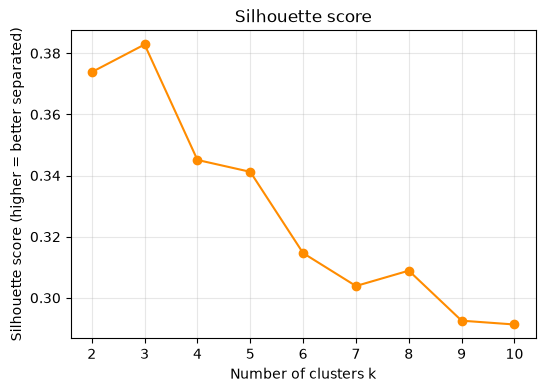

In [7]:
segmentation.plot_k_selection(k_scores);

**Choosing k = 4.** The elbow bends at k = 3-4: inertia drops by about 1,870 from k=2 to 3 and 940 from 3 to 4, but only about 450 from 4 to 5. The silhouette score is highest at k = 3 (0.383) and k = 4 is close (0.345); every larger k is lower. We pick **k = 4** because it is almost as well separated as k = 3 and it splits k = 3's large low-frequency group into regular buyers and one-off buyers, which have clearly different churn rates.

In [8]:
bundle = segmentation.fit_segmentation(train, config.N_SEGMENTS)
train, test = segmentation.add_segments_to_tables(train, test, bundle)
bundle['segment_names']

{1: 'At-Risk', 3: 'Champions', 2: 'One-off buyers', 0: 'Loyal'}

### Segment profile (train)

In [9]:
summary_train = segmentation.segment_summary(train)
summary_train.to_csv(config.TABLES_DIR / 'segment_summary_train.csv')
summary_train

,customers,avg_recency,avg_frequency,avg_monetary,churn_rate,avg_future_spend,share_of_customers
segment_name,,,,,,,
Champions,522,18.512,16.165,9519.546,0.192,3328.152,0.151
Loyal,1229,32.760,4.512,1679.468,0.554,549.013,0.355
One-off buyers,1114,34.948,1.514,396.339,0.778,146.443,0.322
At-Risk,600,130.720,2.190,671.440,0.832,290.882,0.173


### Same segments applied to the test snapshot
Test customers are assigned with the SAVED train scaler and K-Means (`assign_segment`), exactly as the app will do.

In [10]:
summary_test = segmentation.segment_summary(test)
summary_test.to_csv(config.TABLES_DIR / 'segment_summary_test.csv')
summary_test

,customers,avg_recency,avg_frequency,avg_monetary,churn_rate,avg_future_spend,share_of_customers
segment_name,,,,,,,
Champions,705,29.825,18.655,10527.890,0.191,4027.031,0.265
Loyal,825,43.769,5.204,1780.179,0.485,711.475,0.310
One-off buyers,507,42.341,1.558,388.828,0.692,338.908,0.191
At-Risk,621,134.092,3.330,1001.547,0.715,388.303,0.234


**What the segments mean (names come from ranking the real averages; see `name_clusters`):**
- **Champions** (15% of train): bought most recently (about 19 days), very often (about 16 orders) and spent the most (about 9,500 GBP). Churn rate only 0.19.
- **Loyal** (36%): regular buyers, about 4.5 orders, recency about 33 days. Churn rate 0.55.
- **One-off buyers** (32%): recent-ish (about 35 days) but only about 1.5 orders and low spend. Churn rate 0.78.
- **At-Risk** (17%): last order about 131 days before the cutoff, few orders. Churn rate 0.83. They are still *active* by our definition (bought within 180 days), so they are called At-Risk, not Lost.

Churn rate clearly differs by segment (0.19 to 0.83 on train). The same order holds on the test snapshot (0.19, 0.49, 0.69, 0.72), so the segments carry over to new data.

### PCA view of the segments

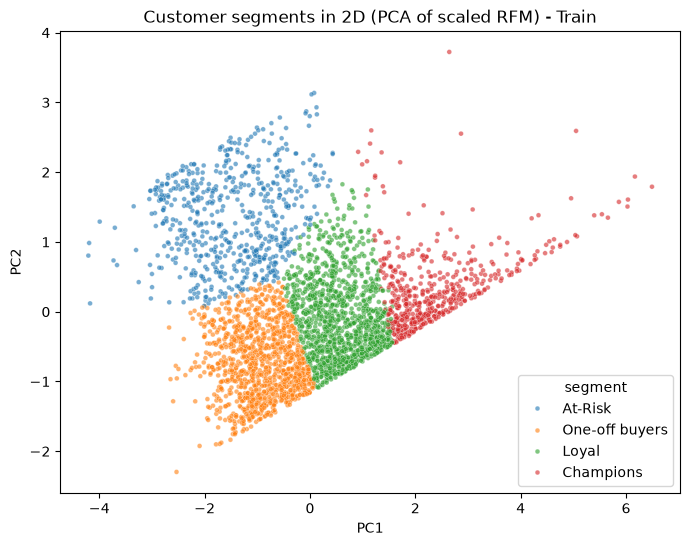

In [11]:
segmentation.plot_pca_segments(train, bundle, 'Train');

**What it shows:** The four segments form separate bands along the first principal component, from At-Risk and One-off buyers on the left to Champions on the right, with Loyal in between. Neighbouring segments touch at their borders, which fits the moderate silhouette score (0.345): the groups are useful but not sharply separated.

In [12]:
train[['segment', 'segment_name']].head()

,segment,segment_name
customer_id,,
12346,1,At-Risk
12347,2,One-off buyers
12348,2,One-off buyers
12349,0,Loyal
12351,2,One-off buyers
